# entropy_tta_probe — Colab 실행 노트북

VLM TTA에서 엔트로피의 한계를 검증하는 E1–E6 실험을 Colab에서 실행합니다.

**사용 순서**
1. 메뉴 `런타임 → 런타임 유형 변경 → GPU(T4 이상)` 선택
2. 아래 **0. 설정** 셀에서 필요한 값만 수정
3. 위에서부터 차례로 실행 (각 단계는 다시 실행해도 이미 끝난 부분은 건너뜀)

**저장 위치**
- 데이터: `/content/data` (런타임 로컬 디스크, 속도 때문). 런타임이 끝나면 사라짐
- 원본 압축 파일: Google Drive `MyDrive/etta_downloads` (다음 세션에 재다운로드 방지)
- 특징 캐시·결과: Google Drive `MyDrive/etta_runs`

**저장소 코드 위치 (중요)**
Colab에서 GitHub의 노트북을 열면 노트북 파일만 열리고 저장소의 나머지 코드(`etta/`, `experiments/`)는 런타임에 없습니다.
1번 셀이 아래 위치를 차례로 찾습니다. 이 중 한 곳에 저장소 폴더를 두세요.
- 현재 작업 폴더 또는 그 상위 폴더 (로컬 Jupyter에서 저장소 안에서 연 경우)
- `/content/entropy_tta_probe` (런타임에 직접 올린 경우)
- `MyDrive/entropy_tta_probe` (Drive에 저장소 폴더를 둔 경우, **권장**)

## 0. 설정

In [1]:
# ===== 여기만 수정하세요 =====
ARCH = "RN50"            # "RN50" (SwapPrompt) 또는 "ViT-B-16" (TPT)
PRETRAINED = "openai"    # CLIP 가중치 (바꿀 필요 없음)
REPO_DIR = ""            # 비워 두면 자동 탐색. 직접 지정하려면 예: "/content/drive/MyDrive/entropy_tta_probe"
USE_DRIVE = True         # 결과·캐시·다운로드 원본을 Google Drive에 보관

# 받을 데이터셋 (True/False). 용량은 대략적인 압축 파일 크기
DATASETS = {
    # --- SwapPrompt cross-dataset 계열 ---
    "dtd":          True,   # 0.6GB
    "oxford_pets":  True,   # 0.8GB
    "flowers102":   True,   # 0.3GB
    "caltech101":   True,   # 0.13GB
    "eurosat":      True,   # 0.09GB
    "ucf101":       True,   # 0.4GB (Google Drive)
    "food101":      False,  # 5GB, 다운로드 느림
    "sun397":       False,  # 37GB, Colab 무료에서는 비권장
    # stanford_cars: 공식 링크가 막혀 있어 자동 다운로드 미지원
    # --- ImageNet 변형 (ImageNet 원본 val은 라이선스 때문에 자동 다운로드 미지원) ---
    "imagenet_a":      True,   # 0.7GB
    "imagenet_r":      True,   # 2GB
    "imagenet_v2":     True,   # 1.2GB
    "imagenet_sketch": False,  # 8.4GB
}

# ImageNet-C 대체: ImageNet-V2 이미지에 ImageNet-C 공식 수식으로 corruption을 직접 생성 (공식 ImageNet-C 아님)
MAKE_V2C = True
V2C_CORRUPTIONS = ["gaussian_noise", "shot_noise", "defocus_blur", "contrast", "jpeg_compression", "pixelate"]
V2C_PER_CLASS = 2        # 클래스당 이미지 수 (1000클래스 × 2 = 2000장 × 6종 × 5단계)

# 실행 규모
N_SAMPLES = 500          # run_episodic.py: 데이터셋당 샘플 수 (전체는 0)
EPISODIC_STEPS = 4       # TPT 업데이트 1..k 스텝 후 예측 기록 (E2의 스텝별 곡선)
WORKERS = 2              # Colab CPU 2개 기준

## 1. 환경 준비: Drive 마운트, 저장소 탐색, 패키지 설치, GPU 확인

In [6]:
import os, sys, glob, subprocess, shutil

IN_COLAB = "google.colab" in sys.modules
DRIVE_ROOT = "/content/drive/MyDrive"
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

def find_repo():
    cands = []
    if REPO_DIR:
        cands.append(REPO_DIR)
    cwd = os.getcwd()
    cands += [cwd, os.path.dirname(cwd), "/content/entropy_tta_probe", f"{DRIVE_ROOT}/entropy_tta_probe"]
    cands += [os.path.dirname(os.path.dirname(p)) for p in glob.glob("/content/*/experiments/run_episodic.py")]
    cands += [os.path.dirname(os.path.dirname(p)) for p in glob.glob(f"{DRIVE_ROOT}/*/experiments/run_episodic.py")]
    for c in cands:
        if c and os.path.isfile(os.path.join(c, "experiments", "run_episodic.py")) and os.path.isdir(os.path.join(c, "etta")):
            return os.path.abspath(c)
    return None

REPO = find_repo()
if REPO is None:
    raise FileNotFoundError(
        "저장소 코드(etta/, experiments/)를 찾지 못했습니다.\n"
        "- Drive의 MyDrive/entropy_tta_probe 에 저장소 폴더를 두거나\n"
        "- 왼쪽 파일 패널에서 /content/entropy_tta_probe 로 업로드한 뒤\n"
        "- 0번 셀의 REPO_DIR에 경로를 지정하고 이 셀을 다시 실행하세요.")
print("repo:", REPO)
if REPO not in sys.path:
    sys.path.insert(0, REPO)

PERSIST = IN_COLAB and USE_DRIVE and os.path.isdir(DRIVE_ROOT)
DATA = "/content/data" if IN_COLAB else os.path.join(REPO, "data")
OUT = f"{DRIVE_ROOT}/etta_runs" if PERSIST else os.path.join(REPO, "etta_runs")
DL = f"{DRIVE_ROOT}/etta_downloads" if PERSIST else os.path.join(DATA, "_downloads")
for d in (DATA, OUT, DL):
    os.makedirs(d, exist_ok=True)
print("data:", DATA, "| results/cache:", OUT, "| downloads:", DL)

subprocess.run([sys.executable, "-m", "pip", "-q", "install", "open_clip_torch", "gdown", "ftfy"], check=True)

import torch
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU만 사용 (매우 느림)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
repo: /content/drive/MyDrive/entropy_tta_probe (1)
data: /content/data | results/cache: /content/drive/MyDrive/etta_runs | downloads: /content/drive/MyDrive/etta_downloads
torch 2.11.0+cu130 | CUDA: True | NVIDIA L4


## 2. 다운로드 도우미

In [7]:
import tarfile, zipfile, urllib.request, json

def fetch(urls, name, gdrive_id=None):
    """urls 중 먼저 성공한 것을 DL/name 에 저장. Drive에 이미 있으면 재사용."""
    dst = os.path.join(DL, name)
    if os.path.isfile(dst) and os.path.getsize(dst) > 0:
        print(f"  cached: {name}")
        return dst
    tmp = dst + ".part"
    if gdrive_id:
        import gdown
        gdown.download(id=gdrive_id, output=tmp, quiet=False)
        if os.path.isfile(tmp) and os.path.getsize(tmp) > 0:
            os.replace(tmp, dst)
            return dst
        raise RuntimeError(f"Google Drive 다운로드 실패: {name} (할당량 초과일 수 있음, 잠시 후 재시도)")
    for u in urls:
        print(f"  downloading {u}")
        r = subprocess.run(["wget", "-q", "--show-progress", "--progress=bar:force:noscroll", "--tries=3", "-O", tmp, u])
        if r.returncode == 0 and os.path.getsize(tmp) > 0:
            os.replace(tmp, dst)
            return dst
        print(f"  failed: {u}")
    if os.path.exists(tmp):
        os.remove(tmp)
    raise RuntimeError(f"모든 링크 실패: {name}")

def extract(archive, to):
    os.makedirs(to, exist_ok=True)
    if archive.endswith(".zip"):
        subprocess.run(["unzip", "-q", "-o", archive, "-d", to], check=True)
    else:
        subprocess.run(["tar", "-xf", archive, "-C", to], check=True)

def find_dir(root, name=None, contains=None):
    """root 아래에서 이름이 name 이거나 하위에 contains 폴더를 가진 디렉터리를 찾음."""
    for dp, dns, _ in os.walk(root):
        if name and os.path.basename(dp) == name:
            return dp
        if contains and contains in dns:
            return dp
    return None

def move_into(src, dst):
    os.makedirs(os.path.dirname(dst), exist_ok=True)
    if os.path.exists(dst):
        shutil.rmtree(dst)
    shutil.move(src, dst)

def gfile(gid, dst):
    """Google Drive의 작은 파일(json/txt)을 dst에 저장 (Drive 캐시 사용)."""
    if os.path.isfile(dst):
        return
    p = fetch([], os.path.basename(dst), gdrive_id=gid)
    os.makedirs(os.path.dirname(dst), exist_ok=True)
    shutil.copy(p, dst)

## 3. 데이터셋 다운로드 및 정리 (CoOp 폴더 구조)

In [8]:
# CoOp(DATASETS.md)이 배포한 split json / 보조 파일의 Google Drive ID
GD = {
    "classnames": "1-61f_ol79pViBFDG_IDlUQSwoLcn2XXF",
    "caltech101": "1hyarUivQE36mY6jSomru6Fjd-JzwcCzN",
    "oxford_pets": "1501r8Ber4nNKvmlFVQZ8SeUHTcdTTEqs",
    "flowers102": "1Pp0sRXzZFZq15zVOzKjKBu4A9i01nozT",
    "food101": "1QK0tGi096I0Ba6kggatX1ee6dJFIcEJl",
    "sun397": "1y2RD81BYuiyvebdN-JymPfyWYcd8_MUq",
    "dtd": "1u3_QfB467jqHgNXC00UIzbLZRQCg2S7x",
    "eurosat": "1Ip7yaCWFi0eaOFUGga0lUdVi_DDQth1o",
    "ucf101_split": "1I0S0q91hJfsV9Gf4xDIjgDq4AqBNJb1y",
    "ucf101_frames": "10Jqome3vtUA2keJkNanAiFpgbyC9Hc2O",
}
TMP = os.path.join(DATA, "_tmp")

def done(path):
    return os.path.isdir(path) and len(os.listdir(path)) > 0

def prep_classnames():
    dst = f"{DATA}/imagenet/classnames.txt"
    if os.path.isfile(dst):
        return
    try:
        gfile(GD["classnames"], dst)
    except Exception as e:
        # 대체: wnid 순서(Keras 인덱스) + open_clip의 CLIP 정제 클래스명 (둘 다 wnid 정렬 순서)
        print("  classnames.txt Google Drive 실패 → 대체 생성:", e)
        from open_clip import IMAGENET_CLASSNAMES
        idx = json.load(urllib.request.urlopen(
            "https://storage.googleapis.com/download.tensorflow.org/data/imagenet_class_index.json"))
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        with open(dst, "w") as f:
            for i in range(1000):
                f.write(f"{idx[str(i)][0]} {IMAGENET_CLASSNAMES[i]}\n")

def prep_dtd():
    if not done(f"{DATA}/dtd/images"):
        a = fetch(["https://www.robots.ox.ac.uk/~vgg/data/dtd/download/dtd-r1.0.1.tar.gz"], "dtd-r1.0.1.tar.gz")
        extract(a, TMP); move_into(find_dir(TMP, name="dtd"), f"{DATA}/dtd")
    gfile(GD["dtd"], f"{DATA}/dtd/split_zhou_DescribableTextures.json")

def prep_oxford_pets():
    if not done(f"{DATA}/oxford_pets/images"):
        a = fetch(["https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz"], "pets_images.tar.gz")
        extract(a, TMP); move_into(find_dir(TMP, name="images"), f"{DATA}/oxford_pets/images")
    gfile(GD["oxford_pets"], f"{DATA}/oxford_pets/split_zhou_OxfordPets.json")

def prep_flowers102():
    if not done(f"{DATA}/oxford_flowers/jpg"):
        a = fetch(["https://www.robots.ox.ac.uk/~vgg/data/flowers/102/102flowers.tgz"], "102flowers.tgz")
        extract(a, TMP); move_into(find_dir(TMP, name="jpg"), f"{DATA}/oxford_flowers/jpg")
    gfile(GD["flowers102"], f"{DATA}/oxford_flowers/split_zhou_OxfordFlowers.json")

def prep_caltech101():
    if not done(f"{DATA}/caltech-101/101_ObjectCategories"):
        a = fetch(["https://data.caltech.edu/records/mzrjq-6wc02/files/caltech-101.zip"], "caltech-101.zip")
        extract(a, TMP)
        inner = glob.glob(f"{TMP}/**/101_ObjectCategories.tar.gz", recursive=True)
        if inner:
            extract(inner[0], f"{TMP}/c101")
        move_into(find_dir(TMP, name="101_ObjectCategories"), f"{DATA}/caltech-101/101_ObjectCategories")
    gfile(GD["caltech101"], f"{DATA}/caltech-101/split_zhou_Caltech101.json")

def prep_eurosat():
    if not done(f"{DATA}/eurosat/2750"):
        a = fetch(["https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip",
                   "http://madm.dfki.de/files/sentinel/EuroSAT.zip"], "EuroSAT_RGB.zip")
        extract(a, TMP); move_into(find_dir(TMP, contains="AnnualCrop"), f"{DATA}/eurosat/2750")
    gfile(GD["eurosat"], f"{DATA}/eurosat/split_zhou_EuroSAT.json")

def prep_ucf101():
    if not done(f"{DATA}/ucf101/UCF-101-midframes"):
        a = fetch([], "UCF-101-midframes.zip", gdrive_id=GD["ucf101_frames"])
        extract(a, TMP); move_into(find_dir(TMP, name="UCF-101-midframes"), f"{DATA}/ucf101/UCF-101-midframes")
    gfile(GD["ucf101_split"], f"{DATA}/ucf101/split_zhou_UCF101.json")

def prep_food101():
    if not done(f"{DATA}/food-101/images"):
        a = fetch(["http://data.vision.ee.ethz.ch/cvl/food-101.tar.gz"], "food-101.tar.gz")
        extract(a, TMP); move_into(find_dir(TMP, name="food-101"), f"{DATA}/food-101")
    gfile(GD["food101"], f"{DATA}/food-101/split_zhou_Food101.json")

def prep_sun397():
    if not done(f"{DATA}/sun397/SUN397"):
        a = fetch(["http://vision.princeton.edu/projects/2010/SUN/SUN397.tar.gz"], "SUN397.tar.gz")
        extract(a, TMP); move_into(find_dir(TMP, name="SUN397"), f"{DATA}/sun397/SUN397")
    gfile(GD["sun397"], f"{DATA}/sun397/split_zhou_SUN397.json")

def prep_imagenet_a():
    if not done(f"{DATA}/imagenet-adversarial/imagenet-a"):
        a = fetch(["https://people.eecs.berkeley.edu/~hendrycks/imagenet-a.tar"], "imagenet-a.tar")
        extract(a, TMP); move_into(find_dir(TMP, name="imagenet-a"), f"{DATA}/imagenet-adversarial/imagenet-a")

def prep_imagenet_r():
    if not done(f"{DATA}/imagenet-rendition/imagenet-r"):
        a = fetch(["https://people.eecs.berkeley.edu/~hendrycks/imagenet-r.tar"], "imagenet-r.tar")
        extract(a, TMP); move_into(find_dir(TMP, name="imagenet-r"), f"{DATA}/imagenet-rendition/imagenet-r")

def prep_imagenet_v2():
    tgt = f"{DATA}/imagenetv2/imagenetv2-matched-frequency-format-val"
    if not done(tgt):
        a = fetch(["https://huggingface.co/datasets/vaishaal/ImageNetV2/resolve/main/imagenetv2-matched-frequency.tar.gz"],
                  "imagenetv2-matched-frequency.tar.gz")
        extract(a, TMP); move_into(find_dir(TMP, name="imagenetv2-matched-frequency-format-val"), tgt)

def prep_imagenet_sketch():
    if not done(f"{DATA}/imagenet-sketch/images"):
        a = fetch(["https://huggingface.co/datasets/songweig/imagenet_sketch/resolve/main/data/ImageNet-Sketch.zip"],
                  "ImageNet-Sketch.zip")
        extract(a, TMP); move_into(find_dir(TMP, name="sketch"), f"{DATA}/imagenet-sketch/images")

failed = {}
if any(DATASETS.get(k) for k in ("imagenet_a", "imagenet_r", "imagenet_v2", "imagenet_sketch")) or MAKE_V2C:
    try:
        prep_classnames()
    except Exception as e:
        failed["classnames"] = e
for name, on in DATASETS.items():
    if not on:
        continue
    print(f"[{name}]")
    try:
        globals()[f"prep_{name}"]()
    except Exception as e:
        failed[name] = e
        print(f"  !! {name} 실패: {e}")
    finally:
        shutil.rmtree(TMP, ignore_errors=True)
print("\n실패:", {k: str(v)[:120] for k, v in failed.items()} or "없음")

Downloading...
From: https://drive.google.com/uc?id=1-61f_ol79pViBFDG_IDlUQSwoLcn2XXF
To: /content/drive/MyDrive/etta_downloads/classnames.txt.part
100%|██████████| 21.8k/21.8k [00:00<00:00, 33.5MB/s]


[dtd]
  downloading https://www.robots.ox.ac.uk/~vgg/data/dtd/download/dtd-r1.0.1.tar.gz


Downloading...
From: https://drive.google.com/uc?id=1u3_QfB467jqHgNXC00UIzbLZRQCg2S7x
To: /content/drive/MyDrive/etta_downloads/split_zhou_DescribableTextures.json.part
100%|██████████| 564k/564k [00:00<00:00, 2.83MB/s]


[oxford_pets]
  downloading https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz


Downloading...
From: https://drive.google.com/uc?id=1501r8Ber4nNKvmlFVQZ8SeUHTcdTTEqs
To: /content/drive/MyDrive/etta_downloads/split_zhou_OxfordPets.json.part
100%|██████████| 724k/724k [00:01<00:00, 637kB/s]


...

[eurosat]
  downloading https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip


Downloading...
From: https://drive.google.com/uc?id=1Ip7yaCWFi0eaOFUGga0lUdVi_DDQth1o
To: /content/drive/MyDrive/etta_downloads/split_zhou_EuroSAT.json.part
100%|██████████| 3.01M/3.01M [00:00<00:00, 17.1MB/s]


[ucf101]


Downloading...
From (original): https://drive.google.com/uc?id=10Jqome3vtUA2keJkNanAiFpgbyC9Hc2O
From (redirected): https://drive.google.com/uc?id=10Jqome3vtUA2keJkNanAiFpgbyC9Hc2O&confirm=t&uuid=35dd1d2b-e546-40ff-afcb-b7b51bdc22dc
To: /content/drive/MyDrive/etta_downloads/UCF-101-midframes.zip.part
100%|██████████| 140M/140M [00:03<00:00, 45.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=1I0S0q91hJfsV9Gf4xDIjgDq4AqBNJb1y
To: /content/drive/MyDrive/etta_downloads/split_zhou_UCF101.json.part
100%|██████████| 1.56M/1.56M [00:00<00:00, 5.49MB/s]


[imagenet_a]
  downloading https://people.eecs.berkeley.edu/~hendrycks/imagenet-a.tar
[imagenet_r]
  downloading https://people.eecs.berkeley.edu/~hendrycks/imagenet-r.tar
[imagenet_v2]
  downloading https://huggingface.co/datasets/vaishaal/ImageNetV2/resolve/main/imagenetv2-matched-frequency.tar.gz

실패: 없음


## 4. ImageNet-V2-C 생성 (ImageNet-C 대체)

공식 ImageNet-C는 수십 GB라 Colab에서 다루기 어렵습니다. 대신 ImageNet-V2 이미지에 **ImageNet-C 논문(Hendrycks & Dietterich, 2019)의 corruption 수식**을 그대로 적용해
`imagenet-c/<corruption>/<severity>/<wnid>/` 구조로 저장합니다. 코드에서는 `imagenet_c/<corruption>/<severity>` 이름으로 그대로 읽힙니다.
결과를 쓸 때는 **공식 ImageNet-C가 아니라 직접 생성한 ImageNet-V2-C**라고 명시하세요.

In [9]:
import numpy as np, cv2, random, zlib
from PIL import Image
from concurrent.futures import ProcessPoolExecutor

def _disk(radius, alias_blur):
    L = np.arange(-8, 9) if radius <= 8 else np.arange(-radius, radius + 1)
    ksize = (3, 3) if radius <= 8 else (5, 5)
    X, Y = np.meshgrid(L, L)
    k = np.array((X ** 2 + Y ** 2) <= radius ** 2, dtype=np.float32)
    k /= k.sum()
    return cv2.GaussianBlur(k, ksize=ksize, sigmaX=alias_blur)

def corrupt(img, kind, s, rng):
    """img: PIL RGB 224x224, s: 1..5 → PIL. ImageNet-C 공식 구현의 상수를 따름."""
    x = np.asarray(img, dtype=np.float32) / 255.0
    if kind == "gaussian_noise":
        c = [.08, .12, .18, .26, .38][s - 1]
        x = np.clip(x + rng.normal(size=x.shape, scale=c), 0, 1)
    elif kind == "shot_noise":
        c = [60, 25, 12, 5, 3][s - 1]
        x = np.clip(rng.poisson(x * c) / c, 0, 1)
    elif kind == "defocus_blur":
        c = [(3, 0.1), (4, 0.5), (6, 0.5), (8, 0.5), (10, 0.5)][s - 1]
        k = _disk(*c)
        x = np.clip(np.stack([cv2.filter2D(x[..., d], -1, k) for d in range(3)], -1), 0, 1)
    elif kind == "contrast":
        c = [0.4, .3, .2, .1, .05][s - 1]
        m = x.mean(axis=(0, 1), keepdims=True)
        x = np.clip((x - m) * c + m, 0, 1)
    elif kind == "jpeg_compression":
        import io
        q = [25, 18, 15, 10, 7][s - 1]
        buf = io.BytesIO(); img.save(buf, "JPEG", quality=q)
        return Image.open(buf).convert("RGB")
    elif kind == "pixelate":
        c = [0.6, 0.5, 0.4, 0.3, 0.25][s - 1]
        w, h = img.size
        return img.resize((int(w * c), int(h * c)), Image.BOX).resize((w, h), Image.BOX)
    else:
        raise ValueError(kind)
    return Image.fromarray((x * 255).astype(np.uint8))

def _job(args):
    src, wnid, stem, seed = args
    rng = np.random.default_rng(seed)
    img = Image.open(src).convert("RGB")
    img = img.resize((256, int(256 * img.height / img.width)) if img.width < img.height
                     else (int(256 * img.width / img.height), 256), Image.BICUBIC)
    l, t = (img.width - 224) // 2, (img.height - 224) // 2
    img = img.crop((l, t, l + 224, t + 224))
    for kind in V2C_CORRUPTIONS:
        for s in range(1, 6):
            d = f"{DATA}/imagenet-c/{kind}/{s}/{wnid}"
            os.makedirs(d, exist_ok=True)
            p = f"{d}/{stem}.JPEG"
            if not os.path.exists(p):
                corrupt(img, kind, s, rng).save(p, quality=85)  # 공식 ImageNet-C와 같이 JPEG q85로 저장

def make_v2c():
    v2 = f"{DATA}/imagenetv2/imagenetv2-matched-frequency-format-val"
    if not done(v2):
        print("ImageNet-V2가 없어 건너뜀 (DATASETS['imagenet_v2']=True 필요)"); return
    wnids = [l.split(" ", 1)[0] for l in open(f"{DATA}/imagenet/classnames.txt") if l.strip()]
    rnd = random.Random(0)
    jobs = []
    for k, w in enumerate(wnids):
        files = sorted(glob.glob(f"{v2}/{k}/*"))
        rnd.shuffle(files)
        for f in files[:V2C_PER_CLASS]:
            stem = os.path.splitext(os.path.basename(f))[0]
            jobs.append((f, w, stem, zlib.crc32(f"{w}/{stem}".encode())))
    print(f"{len(jobs)} images × {len(V2C_CORRUPTIONS)} corruptions × 5 severities")
    import multiprocessing as mp
    with ProcessPoolExecutor(max_workers=max(2, os.cpu_count() or 2), mp_context=mp.get_context("fork")) as ex:
        for i, _ in enumerate(ex.map(_job, jobs, chunksize=16)):
            if (i + 1) % 500 == 0:
                print(f"  {i + 1}/{len(jobs)}")
    print("done")

if MAKE_V2C:
    make_v2c()

2000 images × 6 corruptions × 5 severities
  500/2000
  1000/2000
  1500/2000
  2000/2000
done


## 5. 사용 가능한 데이터셋 확인

In [10]:
import importlib
import etta.data as D
importlib.reload(D)

CANDIDATES = ["imagenet", "imagenet_v2", "imagenet_a", "imagenet_r", "imagenet_sketch",
              "caltech101", "dtd", "flowers102", "oxford_pets", "ucf101",
              "stanford_cars", "food101", "eurosat", "sun397", "fgvc_aircraft"]

def available(names):
    ok = []
    for n in names:
        try:
            s = D.build_split(n, DATA)
            if len(s.items) > 0 and os.path.isfile(s.items[0][0]):
                ok.append(n); print(f"  OK   {n:28s} {len(s.items):6d} samples, {s.num_classes} classes")
        except Exception as e:
            print(f"  --   {n:28s} ({type(e).__name__})")
    return ok

print("기본 데이터셋")
MAIN = available(CANDIDATES)
V2C_ALL = [f"imagenet_c/{c}/{s}" for c in V2C_CORRUPTIONS for s in range(1, 6)]
print("\nImageNet-V2-C")
V2C = available(V2C_ALL) if MAKE_V2C else []
V2C_SEV5 = [n for n in V2C if n.endswith("/5")]
K_SOURCE = next((k for k in ["imagenet", "imagenet_v2", "imagenet_sketch"] if k in MAIN), "none")
print(f"\nMAIN={len(MAIN)}개, V2C={len(V2C)}개, E5 클래스 수 실험 기준: {K_SOURCE}")

기본 데이터셋
  --   imagenet                     (FileNotFoundError)
  OK   imagenet_v2                   10000 samples, 1000 classes
  OK   imagenet_a                     7500 samples, 200 classes
  OK   imagenet_r                    30000 samples, 200 classes
  --   imagenet_sketch              (FileNotFoundError)
  OK   caltech101                     2465 samples, 100 classes
  OK   dtd                            1692 samples, 47 classes
  OK   flowers102                     2463 samples, 102 classes
  OK   oxford_pets                    3669 samples, 37 classes
  OK   ucf101                         3783 samples, 101 classes
  --   stanford_cars                (FileNotFoundError)
  --   food101                      (FileNotFoundError)
  OK   eurosat                        8100 samples, 10 classes
  --   sun397                       (FileNotFoundError)
  --   fgvc_aircraft                (FileNotFoundError)

ImageNet-V2-C
  OK   imagenet_c/gaussian_noise/1    2000 samples, 1000 classes
  

## 실행 도우미

In [11]:
os.environ["TQDM_MININTERVAL"] = "20"   # 진행바 출력 줄이기
COMMON = ["--data_root", DATA, "--arch", ARCH, "--pretrained", PRETRAINED, "--out", f"{OUT}/results", "--cache", f"{OUT}/cache",
          "--workers", str(WORKERS)]

def run(script, *args):
    cmd = [sys.executable, "-u", f"experiments/{script}", *COMMON, *map(str, args)]
    print("$", " ".join(cmd[1:]))
    p = subprocess.Popen(cmd, cwd=REPO, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        print(line, end="")
    if p.wait() != 0:
        raise RuntimeError(f"{script} 실패 (exit {p.returncode})")

## 6. 단계 1 — 특징 캐시 → E1, E5, E6 (빠름)

center-crop 이미지 특징만 쓰는 실험입니다. 데이터셋당 수 분 내외.
- **E1**: 낮은 엔트로피 ≠ 정답, corruption 강도별 추세
- **E5**: 엔트로피 크기의 온도·클래스 수·템플릿 의존성
- **E6**: 클래스 간 의미 구조를 엔트로피가 반영하지 못함

In [12]:
run("cache_features.py", "--datasets", *MAIN, *V2C)
run("e1_entropy_vs_correctness.py", "--datasets", *MAIN, *V2C)
run("e5_scale_sensitivity.py", "--datasets", *MAIN, "--k_source", K_SOURCE)
run("e6_semantic_blindness.py", "--datasets", *MAIN)

$ -u experiments/cache_features.py --data_root /content/data --arch RN50 --pretrained openai --out /content/drive/MyDrive/etta_runs/results --cache /content/drive/MyDrive/etta_runs/cache --workers 2 --datasets imagenet_v2 imagenet_a imagenet_r caltech101 dtd flowers102 oxford_pets ucf101 eurosat imagenet_c/gaussian_noise/1 imagenet_c/gaussian_noise/2 imagenet_c/gaussian_noise/3 imagenet_c/gaussian_noise/4 imagenet_c/gaussian_noise/5 imagenet_c/shot_noise/1 imagenet_c/shot_noise/2 imagenet_c/shot_noise/3 imagenet_c/shot_noise/4 imagenet_c/shot_noise/5 imagenet_c/defocus_blur/1 imagenet_c/defocus_blur/2 imagenet_c/defocus_blur/3 imagenet_c/defocus_blur/4 imagenet_c/defocus_blur/5 imagenet_c/contrast/1 imagenet_c/contrast/2 imagenet_c/contrast/3 imagenet_c/contrast/4 imagenet_c/contrast/5 imagenet_c/jpeg_compression/1 imagenet_c/jpeg_compression/2 imagenet_c/jpeg_compression/3 imagenet_c/jpeg_compression/4 imagenet_c/jpeg_compression/5 imagenet_c/pixelate/1 imagenet_c/pixelate/2 imagenet_

## 7. 단계 2 — TPT episodic → E2, E3 (가장 오래 걸림)

샘플마다 64개 뷰를 만들고 TPT를 `EPISODIC_STEPS`번까지 적용합니다. T4 기준 대략 데이터셋당 수십 분입니다.
- 끊기면 이 셀을 다시 실행하세요. 끝난 데이터셋은 건너뜁니다.
- 1000클래스 데이터셋(ImageNet-V2, Sketch)에서 GPU 메모리가 부족하면 `EPISODIC_STEPS`를 1로 줄이거나 `EPISODIC_SETS`에서 빼세요.

In [13]:
EPISODIC_SETS = MAIN          # 일부만 돌리려면 예: ["dtd", "eurosat", "imagenet_a"]
for ds in EPISODIC_SETS:
    run("run_episodic.py", "--datasets", ds, "--n_samples", N_SAMPLES, "--steps", EPISODIC_STEPS)
run("e2_overconfidence.py")
run("e3_view_selection.py")

$ -u experiments/run_episodic.py --data_root /content/data --arch RN50 --pretrained openai --out /content/drive/MyDrive/etta_runs/results --cache /content/drive/MyDrive/etta_runs/cache --workers 2 --datasets imagenet_v2 --n_samples 500 --steps 4
/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(

imagenet_v2: 100%|██████████| 500/500 [26:18<00:00,  3.16s/it]
imagenet_v2: zero-shot 0.5320  TPT(1 step) 0.5800
$ -u experiments/run_episodic.py --data_root /content/data --arch RN50 --pretrained openai --out /content/drive/MyDrive/etta_runs/results --cache /content/drive/MyDrive/etta_runs/cache --workers 2 --datasets imagenet_a --n_samples 500 --steps 4
/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=Tru

## 8. 단계 3 — 온라인 연속 적응 → E4

리셋 없이 엔트로피 최소화를 이어갈 때의 오류 누적과 붕괴를 봅니다.
스트림은 ImageNet-V2-C severity 5의 corruption들을 차례로 이어 붙인 것이고, 없으면 ImageNet 변형으로 대체합니다.

In [14]:
STREAM = V2C_SEV5 or [d for d in ["imagenet_a", "imagenet_r", "imagenet_sketch", "imagenet_v2"] if d in MAIN]
print("stream:", STREAM)
for order in ["iid", "dirichlet", "class_sorted"]:
    run("e4_continual_collapse.py", "--datasets", *STREAM, "--order", order)
run("e4_continual_collapse.py", "--datasets", *STREAM, "--order", "dirichlet", "--objective", "ent_div")
run("e4_continual_collapse.py", "--datasets", *STREAM, "--order", "iid", "--params", "norm", "--lr", "1e-3")

stream: ['imagenet_c/gaussian_noise/5', 'imagenet_c/shot_noise/5', 'imagenet_c/defocus_blur/5', 'imagenet_c/contrast/5', 'imagenet_c/jpeg_compression/5', 'imagenet_c/pixelate/5']
$ -u experiments/e4_continual_collapse.py --data_root /content/data --arch RN50 --pretrained openai --out /content/drive/MyDrive/etta_runs/results --cache /content/drive/MyDrive/etta_runs/cache --workers 2 --datasets imagenet_c/gaussian_noise/5 imagenet_c/shot_noise/5 imagenet_c/defocus_blur/5 imagenet_c/contrast/5 imagenet_c/jpeg_compression/5 imagenet_c/pixelate/5 --order iid
/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(
imagenet_c/gaussian_noise/5: streamed 2000 samples
imagenet_c/shot_noise/5: streamed 2000 samples
imagenet_c/defocus_blur/5: streamed 2000 samples
imagenet_c/contrast/5: streamed 2000 samples
imagenet_c/jpeg_compression/5: streamed 

## 9. 결과 보기

### E1  `/content/drive/MyDrive/etta_runs/results/e1/RN50_openai`

`summary.csv`

,dataset,acc,auroc_negH_correct,err_in_lowest10pct_H,share_of_errors_below_median_H,mean_conf_of_errors
0,imagenet_v2,0.5003,0.7539,0.0660,0.3134,0.3369
1,imagenet_a,0.2236,0.6603,0.5720,0.4486,0.3511
2,imagenet_r,0.5664,0.8264,0.0127,0.2183,0.3234
3,caltech101,0.8438,0.8604,0.0000,0.0623,0.4919
4,dtd,0.4001,0.7729,0.0412,0.3478,0.3426
5,flowers102,0.5782,0.8251,0.0324,0.2079,0.3726
6,oxford_pets,0.8051,0.8328,0.0000,0.1091,0.4916
7,ucf101,0.5847,0.8163,0.0079,0.2139,0.3487
8,eurosat,0.2601,0.7540,0.2765,0.4145,0.2888
9,imagenet_c/gaussian_noise/1,0.3675,0.7657,0.1300,0.3636,0.2466


`imagenet_c_by_severity.csv`

,acc,auroc_negH_correct,err_in_lowest10pct_H,share_of_errors_below_median_H,mean_conf_of_errors,severity
0,0.3752,0.7481,0.1683,0.3659,0.2443,1
1,0.3133,0.7413,0.2683,0.3904,0.2140,2
2,0.2308,0.7369,0.4083,0.4257,0.1664,3
3,0.1287,0.7526,0.6058,0.4550,0.1053,4
4,0.0650,0.7536,0.7633,0.4777,0.0742,5


`entropy_deciles.png`

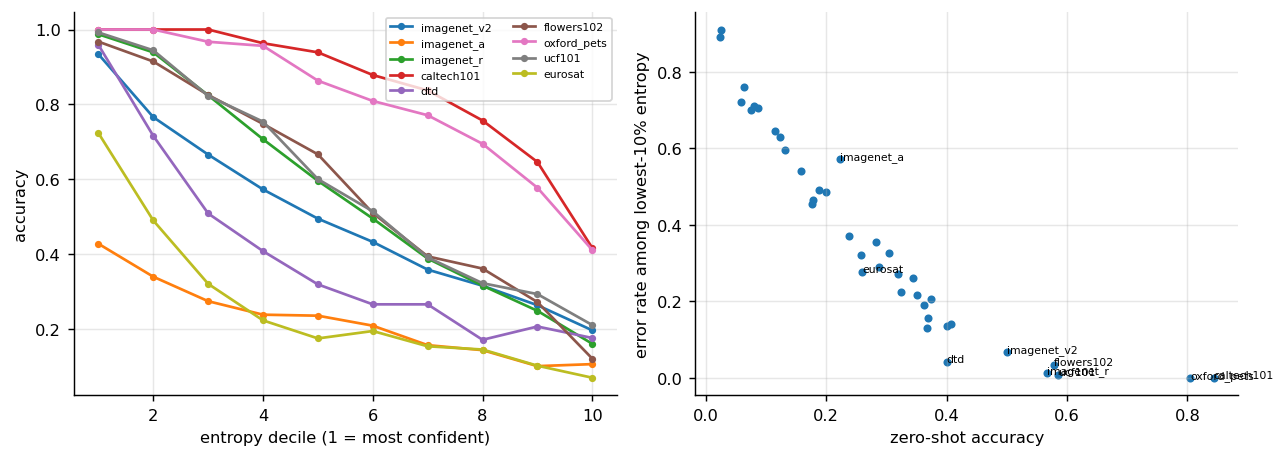

`imagenet_c_severity.png`

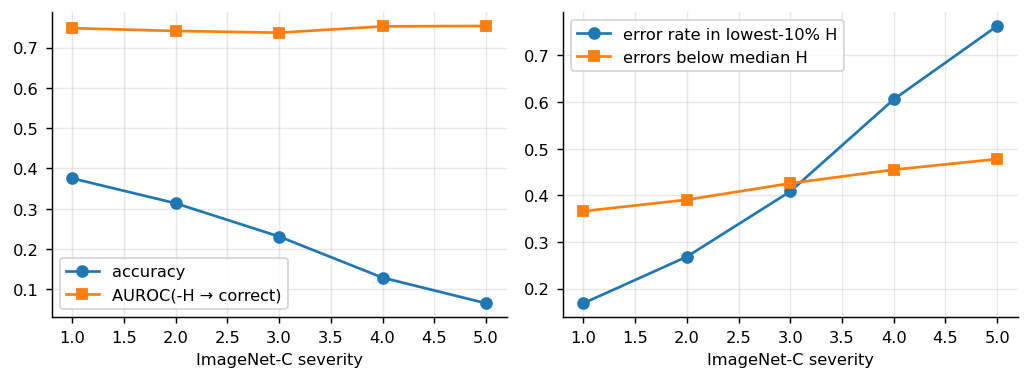

### E2  `/content/drive/MyDrive/etta_runs/results/e2/RN50_openai`

`flips.csv`

,dataset,n,R_to_W,W_to_R,W_to_W,R_to_R,W_to_W_conf_up,mean_dconf_W_to_W,mean_dconf_R_to_R,conf_wrong_gt90_zs,conf_wrong_gt90_tpt
0,caltech101,500,0.014,0.036,0.130,0.820,0.8154,0.2044,0.0820,0.006,0.038
1,dtd,500,0.032,0.050,0.542,0.376,0.9483,0.2439,0.2032,0.004,0.076
2,eurosat,500,0.070,0.136,0.636,0.158,0.8836,0.1402,0.2041,0.000,0.002
3,flowers102,500,0.026,0.038,0.372,0.564,0.8817,0.1640,0.1527,0.004,0.042
4,imagenet_a,500,0.024,0.076,0.674,0.226,0.8665,0.1626,0.2350,0.012,0.052
5,imagenet_r,500,0.038,0.048,0.384,0.530,0.8906,0.1668,0.1436,0.008,0.032
6,imagenet_v2,500,0.028,0.076,0.392,0.504,0.8571,0.1669,0.1886,0.006,0.034
7,oxford_pets,500,0.020,0.030,0.152,0.798,0.9211,0.1901,0.1106,0.000,0.036
8,ucf101,500,0.024,0.036,0.364,0.576,0.9011,0.1788,0.1602,0.004,0.030


`overconfidence.png`

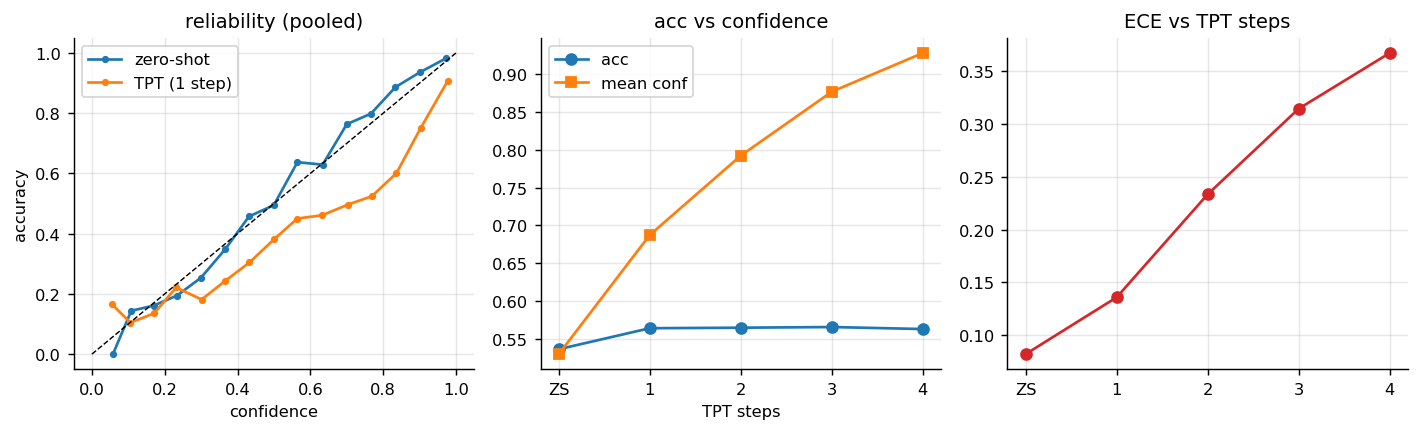

### E3  `/content/drive/MyDrive/etta_runs/results/e3/RN50_openai`

`summary.csv`

,dataset,n,acc_orig,acc_all_views,acc_selected_views,acc_zero_vote,acc_tpt,tpt_agrees_with_zero,tpt_agrees_with_sel_ens,view_acc_selected,view_acc_unselected,view_acc_most_confident_bin,view_acc_least_confident_bin,area_selected,area_unselected,orig_view_selected,unanimous_wrong,harm_orig_right_sel_wrong,help_orig_wrong_sel_right
0,caltech101,500,0.834,0.852,0.862,0.862,0.856,0.968,0.974,0.8467,0.6561,0.8432,0.2374,0.5381,0.3839,0.258,0.066,0.018,0.046
1,dtd,500,0.410,0.400,0.424,0.424,0.426,0.840,0.842,0.4130,0.3641,0.4122,0.2566,0.4864,0.4406,0.156,0.294,0.036,0.050
2,eurosat,500,0.228,0.254,0.254,0.252,0.294,0.656,0.662,0.2553,0.1978,0.2612,0.1389,0.5098,0.4823,0.074,0.176,0.100,0.126
3,flowers102,500,0.590,0.586,0.586,0.580,0.602,0.872,0.874,0.5687,0.4830,0.5680,0.2429,0.5081,0.4215,0.210,0.162,0.040,0.036
4,imagenet_a,500,0.246,0.310,0.366,0.362,0.302,0.722,0.728,0.3397,0.2065,0.3328,0.0654,0.4048,0.4232,0.098,0.186,0.040,0.160
5,imagenet_r,500,0.566,0.556,0.568,0.568,0.578,0.826,0.830,0.5517,0.3920,0.5490,0.1237,0.5124,0.4208,0.194,0.148,0.058,0.060
6,imagenet_v2,500,0.532,0.574,0.556,0.560,0.580,0.826,0.822,0.5427,0.4169,0.5402,0.1651,0.4527,0.4090,0.132,0.132,0.058,0.082
7,oxford_pets,500,0.818,0.832,0.828,0.828,0.828,0.944,0.946,0.8153,0.6790,0.8140,0.2880,0.4997,0.4047,0.170,0.086,0.020,0.030
8,ucf101,500,0.598,0.574,0.602,0.606,0.612,0.872,0.864,0.5877,0.4182,0.5868,0.1194,0.5470,0.4201,0.182,0.126,0.048,0.052


`view_selection.png`

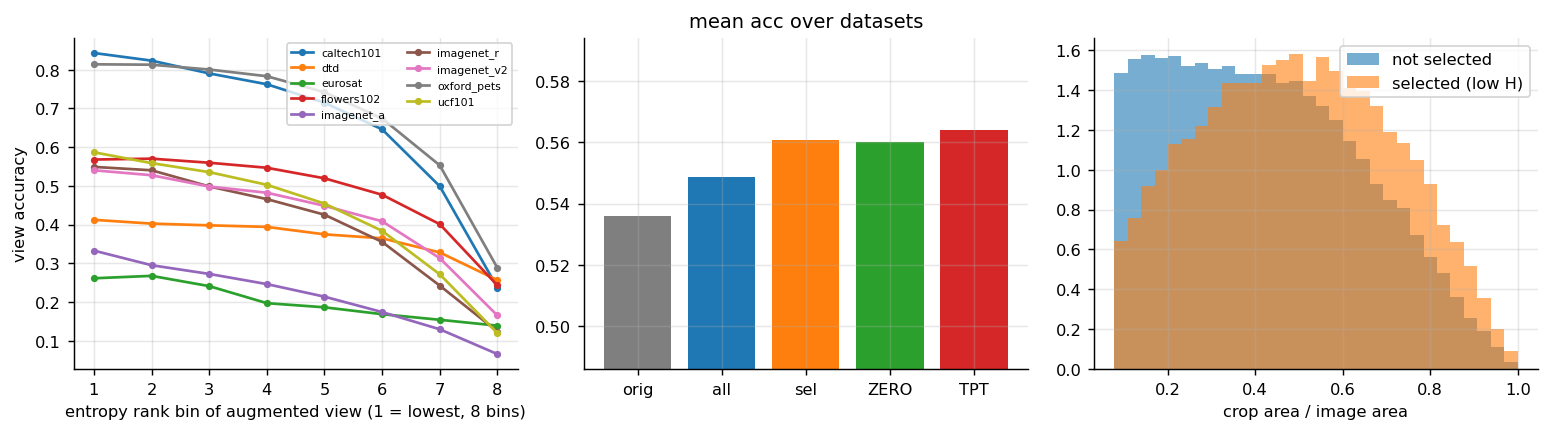

### E4  `/content/drive/MyDrive/etta_runs/results/e4/RN50_openai`

`norm_iid_ent_lr0.001_s1/final_eval.csv`

,dataset,zero_shot_acc,online_acc,final_params_acc,final_distinct_pred_classes,num_classes
0,imagenet_c/gaussian_noise/5,0.0235,0.0060,0.0055,287,1000
1,imagenet_c/shot_noise/5,0.0250,0.0100,0.0055,299,1000
2,imagenet_c/defocus_blur/5,0.0805,0.0175,0.0115,360,1000
3,imagenet_c/contrast/5,0.0590,0.0290,0.0265,423,1000
4,imagenet_c/jpeg_compression/5,0.1150,0.0400,0.0340,375,1000
5,imagenet_c/pixelate/5,0.0870,0.0395,0.0415,410,1000


`prompt_class_sorted_ent_lr0.005_s1/final_eval.csv`

,dataset,zero_shot_acc,online_acc,final_params_acc,final_distinct_pred_classes,num_classes
0,imagenet_c/gaussian_noise/5,0.0235,0.004,0.001,1,1000
1,imagenet_c/shot_noise/5,0.0250,0.001,0.001,1,1000
2,imagenet_c/defocus_blur/5,0.0805,0.001,0.001,1,1000
3,imagenet_c/contrast/5,0.0590,0.001,0.001,1,1000
4,imagenet_c/jpeg_compression/5,0.1150,0.001,0.001,1,1000
5,imagenet_c/pixelate/5,0.0870,0.001,0.001,1,1000


...

`prompt_dirichlet_ent_lr0.005_s1/final_eval.csv`

,dataset,zero_shot_acc,online_acc,final_params_acc,final_distinct_pred_classes,num_classes
0,imagenet_c/gaussian_noise/5,0.0235,0.0025,0.001,1,1000
1,imagenet_c/shot_noise/5,0.0250,0.0010,0.001,1,1000
2,imagenet_c/defocus_blur/5,0.0805,0.0025,0.001,1,1000
3,imagenet_c/contrast/5,0.0590,0.0010,0.001,1,1000
4,imagenet_c/jpeg_compression/5,0.1150,0.0010,0.001,1,1000
5,imagenet_c/pixelate/5,0.0870,0.0010,0.001,1,1000


`prompt_iid_ent_lr0.005_s1/final_eval.csv`

,dataset,zero_shot_acc,online_acc,final_params_acc,final_distinct_pred_classes,num_classes
0,imagenet_c/gaussian_noise/5,0.0235,0.0045,0.001,1,1000
1,imagenet_c/shot_noise/5,0.0250,0.0010,0.001,1,1000
2,imagenet_c/defocus_blur/5,0.0805,0.0010,0.001,1,1000
3,imagenet_c/contrast/5,0.0590,0.0010,0.001,1,1000
4,imagenet_c/jpeg_compression/5,0.1150,0.0010,0.001,1,1000
5,imagenet_c/pixelate/5,0.0870,0.0010,0.001,1,1000


`norm_iid_ent_lr0.001_s1/stream.png`

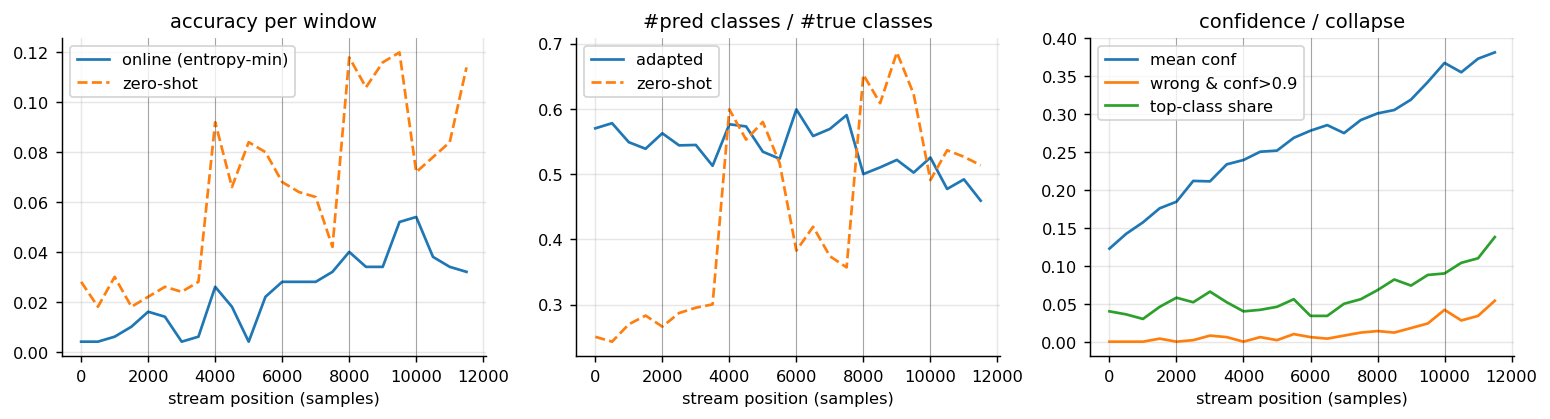

`prompt_class_sorted_ent_lr0.005_s1/stream.png`

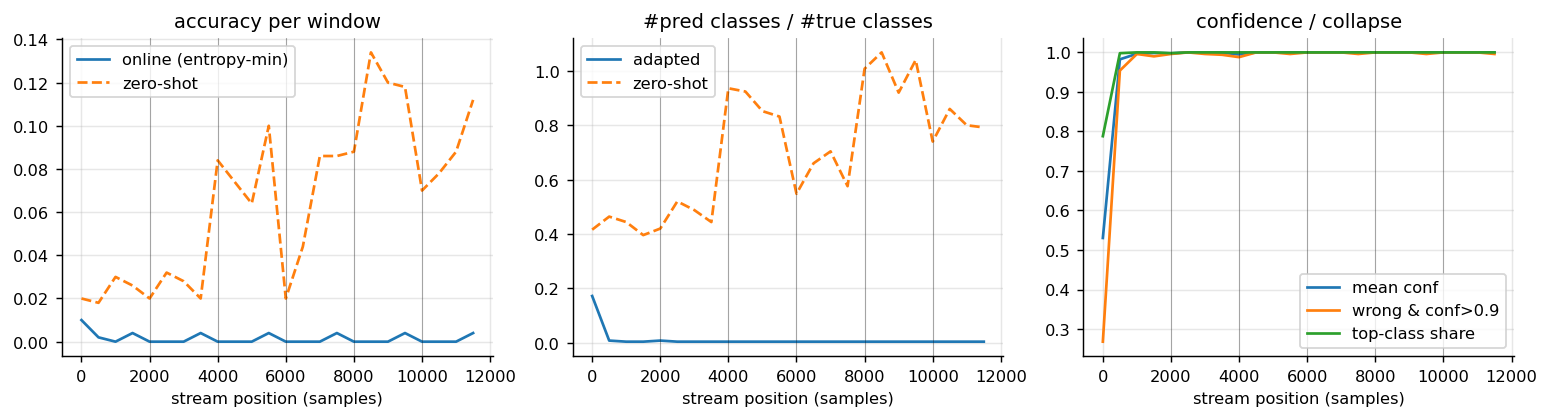

`prompt_dirichlet_ent_div_lr0.005_s1/stream.png`

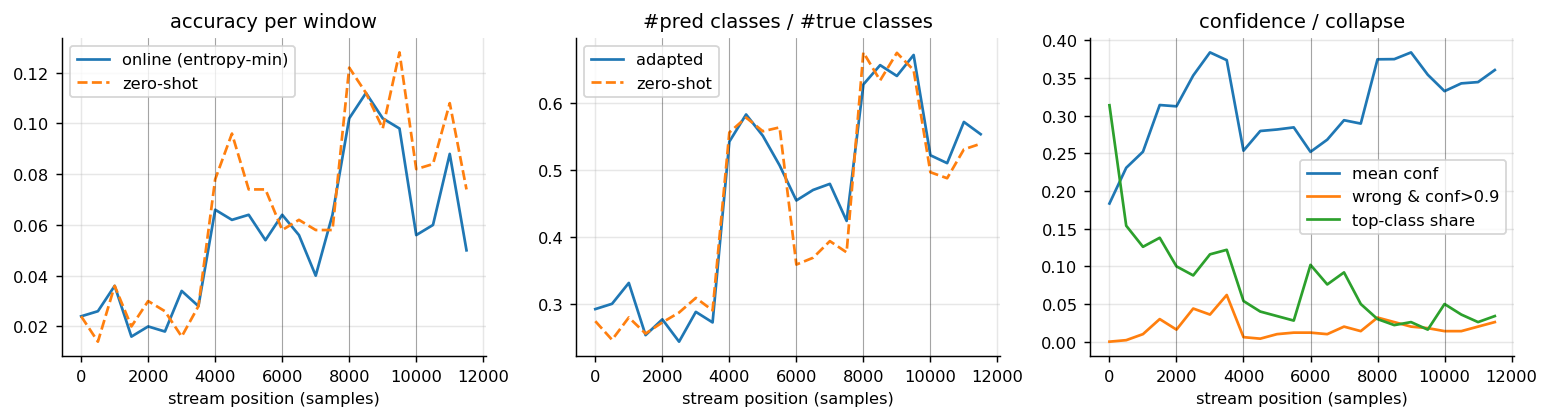

`prompt_dirichlet_ent_lr0.005_s1/stream.png`

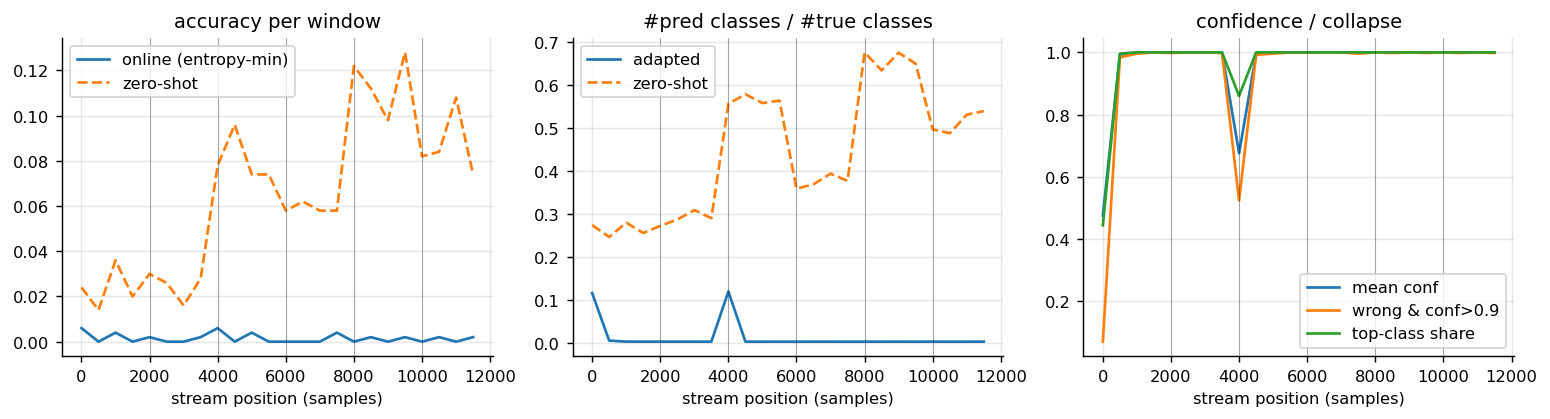

`prompt_iid_ent_lr0.005_s1/stream.png`

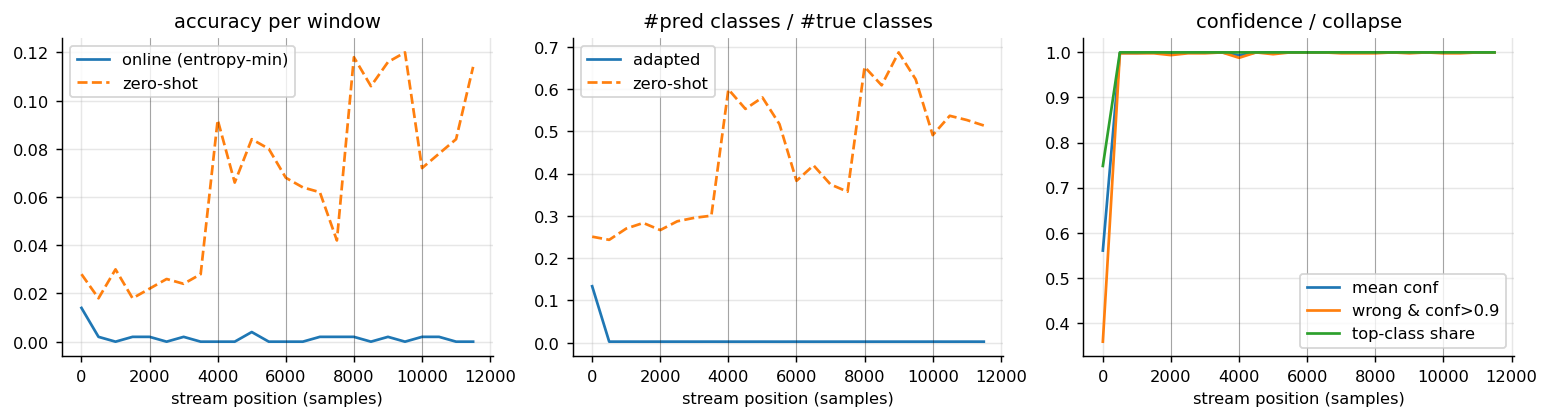

### E5  `/content/drive/MyDrive/etta_runs/results/e5/RN50_openai`

`temperature.csv`

,dataset,K,scale,acc,mean_H,fixed_thr_select_rate,fixed_thr_precision
0,imagenet_v2,1000,25,0.5003,6.6501,0.0000,NaN
1,imagenet_v2,1000,50,0.5003,5.4570,0.0055,0.9818
2,imagenet_v2,1000,100,0.5003,2.3837,0.6132,0.6389
3,imagenet_v2,1000,200,0.5003,0.8351,0.9822,0.5082
4,imagenet_a,200,25,0.2236,5.1033,0.0000,NaN
5,imagenet_a,200,50,0.2236,4.4067,0.0055,0.4634
6,imagenet_a,200,100,0.2236,2.5715,0.5339,0.2972
7,imagenet_a,200,200,0.2236,1.0691,0.9844,0.2263
8,imagenet_r,200,25,0.5664,5.0657,0.0000,NaN
9,imagenet_r,200,50,0.5664,4.0935,0.0653,0.9582


`scale_sensitivity.png`

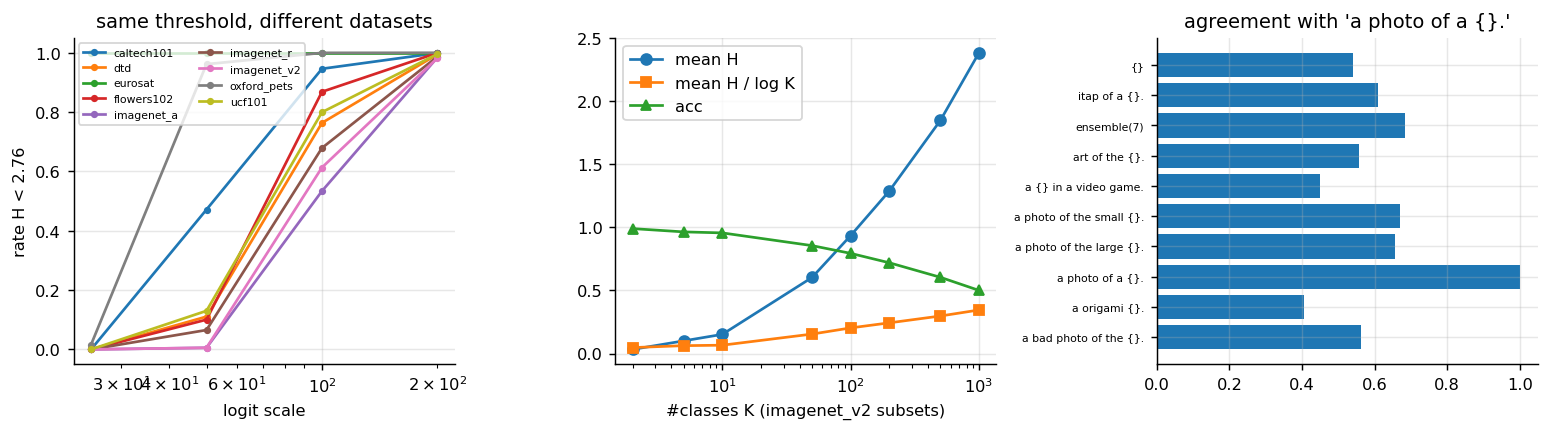

### E6  `/content/drive/MyDrive/etta_runs/results/e6/RN50_openai`

`summary.csv`

,dataset,n,K,acc,auroc_negH_correct,auroc_negQ_correct,auroc_H_near_vs_far_err,auroc_Q_near_vs_far_err,mean_H_near_err,mean_H_far_err,mean_Q_iqr_within_H_decile,mean_text_text_cos,mean_max_img_text_cos,mean_top12_cos_gap_correct,mean_top12_cos_gap_wrong,corr_H_gap
0,imagenet_v2,10000,1000,0.5003,0.7539,0.7520,0.6242,0.7733,2.7066,3.2023,0.0590,0.6387,0.2438,0.0206,0.0084,-0.6571
1,imagenet_a,7500,200,0.2236,0.6603,0.6548,0.5592,0.6568,2.5917,2.7961,0.0486,0.6670,0.2190,0.0144,0.0094,-0.6515
2,imagenet_r,10000,200,0.5608,0.8241,0.8280,0.5993,0.7150,2.6232,2.9534,0.0404,0.6641,0.2204,0.0253,0.0080,-0.7590
3,caltech101,2465,100,0.8438,0.8604,0.8775,0.5670,0.6686,1.7249,1.9470,0.0237,0.6901,0.2348,0.0401,0.0102,-0.7296
4,dtd,1692,47,0.4001,0.7729,0.7705,0.5223,0.6107,2.3742,2.4281,0.0209,0.7745,0.2292,0.0222,0.0079,-0.8270
5,flowers102,2463,102,0.5782,0.8251,0.8145,0.5779,0.7092,2.1903,2.3477,0.0421,0.5907,0.2711,0.0234,0.0081,-0.8220
6,oxford_pets,3669,37,0.8051,0.8328,0.8207,0.6544,0.8167,1.2965,1.5483,0.0288,0.6143,0.2605,0.0240,0.0076,-0.8255
7,ucf101,3783,101,0.5847,0.8163,0.8270,0.7132,0.7632,2.1467,2.6878,0.0257,0.7040,0.2223,0.0242,0.0074,-0.7693
8,eurosat,8100,10,0.2601,0.7540,0.7429,0.4960,0.6098,1.9706,2.0059,0.0090,0.8435,0.1856,0.0069,0.0044,-0.5934


`entropy_vs_rao.png`

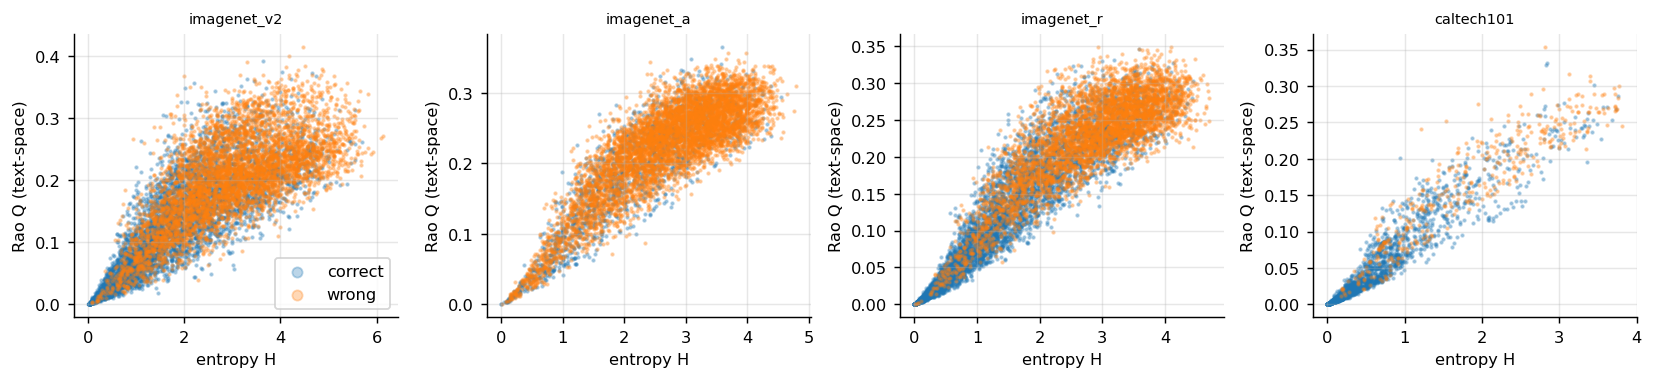

In [15]:
import pandas as pd
from IPython.display import Image as IPImage, display, Markdown
pd.set_option("display.width", 200, "display.max_columns", 30)

R = f"{OUT}/results"
def show(exp, csvs=(), cols=None):
    base = glob.glob(f"{R}/{exp}/{ARCH}_*")
    if not base:
        print(f"{exp}: 결과 없음"); return
    base = base[0]
    display(Markdown(f"### {exp.upper()}  `{base}`"))
    for c in csvs:
        for p in sorted(glob.glob(f"{base}/**/{c}", recursive=True)):
            df = pd.read_csv(p)
            display(Markdown(f"`{os.path.relpath(p, base)}`"))
            display(df[[x for x in (cols or df.columns) if x in df.columns]].round(4))
    for p in sorted(glob.glob(f"{base}/**/*.png", recursive=True)):
        display(Markdown(f"`{os.path.relpath(p, base)}`")); display(IPImage(p, width=900))

show("e1", ["summary.csv", "imagenet_c_by_severity.csv"],
     ["dataset", "acc", "auroc_negH_correct", "err_in_lowest10pct_H", "share_of_errors_below_median_H",
      "mean_conf_of_errors", "severity"])
show("e2", ["flips.csv"])
show("e3", ["summary.csv"])
show("e4", ["final_eval.csv"])
show("e5", ["temperature.csv"], ["dataset", "K", "scale", "acc", "mean_H", "fixed_thr_select_rate", "fixed_thr_precision"])
show("e6", ["summary.csv"])